# Create Dataset

In [1]:

!pip -q install kagglehub opencv-python-headless

import kagglehub
from pathlib import Path

DATASET_PATH = Path(
    kagglehub.dataset_download(
        "oshanyalegama/div2k-dataset"
    )
)

print("Dataset downloaded:", DATASET_PATH)

# สำรวจโครงสร้างโฟลเดอร์ HR
for p in sorted(DATASET_PATH.rglob("*")):
    if p.is_dir() and "hr" in p.name.lower():
        print(p)


Dataset downloaded: /kaggle/input/datasets/oshanyalegama/div2k-dataset
/kaggle/input/datasets/oshanyalegama/div2k-dataset/DIV2K_train_HR
/kaggle/input/datasets/oshanyalegama/div2k-dataset/DIV2K_train_HR/DIV2K_train_HR
/kaggle/input/datasets/oshanyalegama/div2k-dataset/DIV2K_valid_HR
/kaggle/input/datasets/oshanyalegama/div2k-dataset/DIV2K_valid_HR/DIV2K_valid_HR


In [2]:
import random
import numpy as np
import cv2
import csv

from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMAGE_SIZE = 128
# ทุก split ตัดจำนวน patch เท่ากัน เพื่อให้สัดส่วนภาพตรง 70/10/20
PATCHES_TRAIN = 4
PATCHES_VALID = 4
PATCHES_TEST = 4

OUTPUT_DIR = Path("/kaggle/working//DIV2K_Restoration")

# ค้นหาเฉพาะภาพ HR เพื่อไม่ให้ปนภาพ LR
def find_hr_images(root, split):
    folder_name = f"div2k_{split}_hr"

    images = [
        p for p in root.rglob("*")
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
        and any(
            part.lower() == folder_name
            for part in p.parts
        )
    ]

    return sorted(images)

original_train = find_hr_images(DATASET_PATH, "train")
original_valid = find_hr_images(DATASET_PATH, "valid")

print("Original Train:", len(original_train))
print("Original Valid:", len(original_valid))

assert len(original_train) > 0, (
    "ไม่พบ DIV2K_train_HR กรุณาตรวจโฟลเดอร์"
)
assert len(original_valid) > 0, (
    "ไม่พบ DIV2K_valid_HR กรุณาตรวจโฟลเดอร์"
)

# รวมภาพ HR ทั้งหมด (800 + 100 = 900) แล้วแบ่งที่ระดับภาพต้นฉบับ
# Train 70% / Valid 10% / Test 20%
all_files = original_train + original_valid

train_files, test_files = train_test_split(
    all_files,
    test_size=0.2,
    random_state=SEED,
    shuffle=True
)

# เหลือ 80% -> valid = 10% ของทั้งหมด = 1/8 ของส่วนที่เหลือ
train_files, valid_files = train_test_split(
    train_files,
    test_size=1 / 8,
    random_state=SEED,
    shuffle=True
)

splits = {
    "train": train_files,
    "valid": valid_files,
    "test": test_files
}

for split, files in splits.items():
    print(f"{split}: {len(files)} original images")


Original Train: 800
Original Valid: 100
train: 630 original images
valid: 90 original images
test: 180 original images


In [3]:
def add_gaussian_noise(image, rng):
    sigma = rng.uniform(10, 30)

    noise = rng.normal(
        0, sigma, image.shape
    )

    noisy = image.astype(np.float32) + noise

    return np.clip(
        noisy, 0, 255
    ).astype(np.uint8), sigma


def add_gaussian_blur(image, rng):
    kernel_size = int(rng.choice([5, 7, 9, 11]))
    sigma = float(rng.uniform(1.0, 3.0))

    blurred = cv2.GaussianBlur(
        image,
        (kernel_size, kernel_size),
        sigmaX=sigma
    )

    return blurred, sigma


def create_degradations(clean, rng):
    # Noise อย่างเดียว
    noisy, noise_sigma = add_gaussian_noise(
        clean, rng
    )

    # Blur อย่างเดียว
    blurred, blur_sigma = add_gaussian_blur(
        clean, rng
    )

    # ทั้ง Noise + Blur
    combined, combined_noise_sigma = add_gaussian_noise(
        blurred, rng
    )

    return {
        "noise": noisy,
        "blur": blurred,
        "noise_blur": combined
    }, noise_sigma, blur_sigma, combined_noise_sigma


In [4]:
import shutil

def random_crop(image, size, rng):
    h, w = image.shape[:2]

    if h < size or w < size:
        raise ValueError(
            f"Image is too small: {w}x{h}"
        )

    top = int(rng.integers(0, h - size + 1))
    left = int(rng.integers(0, w - size + 1))

    return image[
        top:top + size,
        left:left + size
    ]


def save_rgb(path, image):
    Image.fromarray(image).save(path)


def build_dataset():
    records = []

    for split, files in splits.items():
        patches = {
            "train": PATCHES_TRAIN,
            "valid": PATCHES_VALID,
            "test": PATCHES_TEST
        }[split]

        for category in [
            "clean", "noise", "blur", "noise_blur"
        ]:
            category_dir = OUTPUT_DIR / split / category

            # ล้างภาพจากรอบก่อน เพื่อไม่ให้ปนกับรอบใหม่
            if category_dir.exists():
                shutil.rmtree(category_dir)

            category_dir.mkdir(
                parents=True, exist_ok=True
            )

        print(f"\nProcessing {split}...")

        for idx, path in enumerate(files):
            with Image.open(path) as img:
                image = np.array(
                    img.convert("RGB")
                )

            # Seed คงที่ ทำซ้ำแล้วได้ภาพเดิม
            rng = np.random.default_rng(
                SEED + idx + {
                    "train": 0,
                    "valid": 100000,
                    "test": 200000
                }[split]
            )

            for patch_idx in range(patches):
                clean = random_crop(
                    image, IMAGE_SIZE, rng
                )

                (
                    degraded, noise_sigma, blur_sigma,
                    combined_noise_sigma
                ) = create_degradations(clean, rng)

                filename = (
                    f"{path.stem}_{patch_idx:03d}.png"
                )

                save_rgb(
                    OUTPUT_DIR / split / "clean" / filename,
                    clean
                )

                for category, result in degraded.items():
                    save_rgb(
                        OUTPUT_DIR / split / category / filename,
                        result
                    )

                records.append({
                    "split": split,
                    "source": path.name,
                    "filename": filename,
                    "noise_sigma": round(noise_sigma, 3),
                    "blur_sigma": round(blur_sigma, 3),
                    "combined_noise_sigma": round(combined_noise_sigma, 3)
                })

            if (idx + 1) % 50 == 0:
                print(f"  {idx + 1}/{len(files)} images")

    with open(
        OUTPUT_DIR / "manifest.csv",
        "w",
        newline=""
    ) as f:
        writer = csv.DictWriter(
            f,
            fieldnames=[
                "split", "source", "filename",
                "noise_sigma", "blur_sigma",
                "combined_noise_sigma"
            ]
        )
        writer.writeheader()
        writer.writerows(records)

    print("\nDataset created at:", OUTPUT_DIR)
    return records


records = build_dataset()



Processing train...
  50/630 images
  100/630 images
  150/630 images
  200/630 images
  250/630 images
  300/630 images
  350/630 images
  400/630 images
  450/630 images
  500/630 images
  550/630 images
  600/630 images

Processing valid...
  50/90 images

Processing test...
  50/180 images
  100/180 images
  150/180 images

Dataset created at: /kaggle/working/DIV2K_Restoration


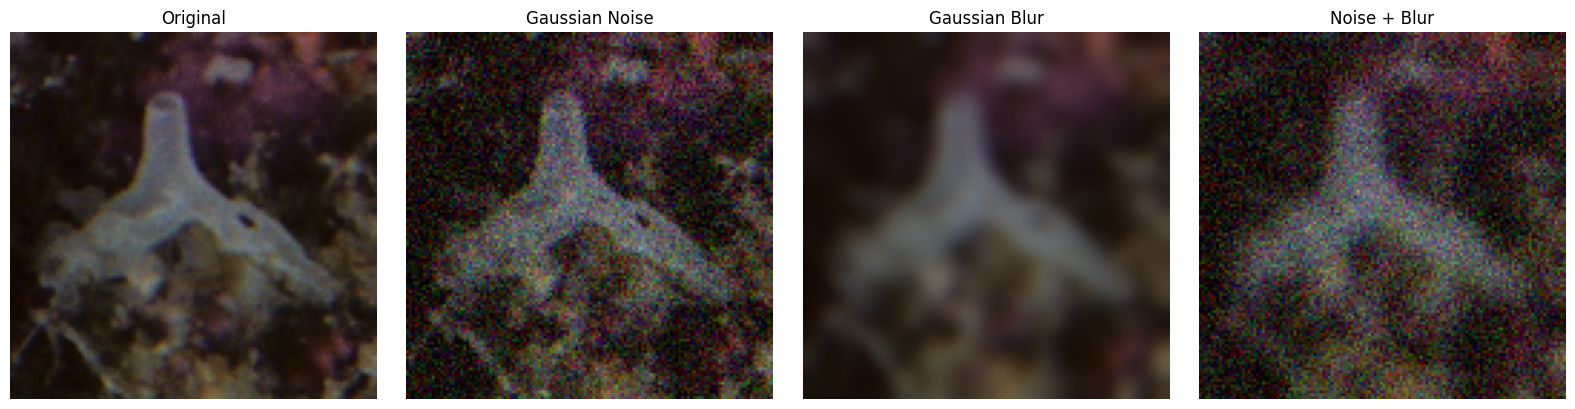

In [5]:
import matplotlib.pyplot as plt

sample_path = sorted(
    (OUTPUT_DIR / "train" / "clean").glob("*.png")
)[0]

filename = sample_path.name

categories = [
    "clean",
    "noise",
    "blur",
    "noise_blur"
]

titles = [
    "Original",
    "Gaussian Noise",
    "Gaussian Blur",
    "Noise + Blur"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, category, title in zip(
    axes, categories, titles
):
    path = OUTPUT_DIR / "train" / category / filename

    img = Image.open(path)
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

# ตรวจ Data Leakage ระหว่าง Source Images
source_sets = {
    name: set(p.name for p in files)
    for name, files in splits.items()
}

assert not (
    source_sets["train"] & source_sets["valid"]
)
assert not (
    source_sets["train"] & source_sets["test"]
)
assert not (
    source_sets["valid"] & source_sets["test"]
)

# ตรวจจำนวนไฟล์แต่ละประเภท
for split in splits:
    counts = {
        category: len(list(
            (OUTPUT_DIR / split / category).glob("*.png")
        ))
        for category in [
            "clean", "noise", "blur", "noise_blur"
        ]
    }

    assert len(set(counts.values())) == 1, counts

    # ตรวจว่าชื่อไฟล์จับคู่กันครบ
    names = [
        {p.name for p in (
            OUTPUT_DIR / split / category
        ).glob("*.png")}
        for category in counts
    ]

    assert all(n == names[0] for n in names)

    print(split, counts)

print("Dataset split and pairing checks passed!")


train {'clean': 2520, 'noise': 2520, 'blur': 2520, 'noise_blur': 2520}
valid {'clean': 360, 'noise': 360, 'blur': 360, 'noise_blur': 360}
test {'clean': 720, 'noise': 720, 'blur': 720, 'noise_blur': 720}
Dataset split and pairing checks passed!


In [7]:

import shutil
from pathlib import Path
from IPython.display import FileLink, display

folder = Path("/kaggle/working/DIV2K_Restoration")

zip_path = shutil.make_archive(
    "/kaggle/working/DIV2K_Restoration",
    "zip",
    root_dir=folder.parent,
    base_dir=folder.name
)

print("ZIP created:", zip_path)
print("Size:", round(Path(zip_path).stat().st_size / 1024**2, 2), "MB")

display(FileLink(zip_path))


ZIP created: /kaggle/working/DIV2K_Restoration.zip
Size: 432.23 MB


/kaggle/working/DIV2K_Restoration.zip

# Train

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

tf.keras.utils.set_random_seed(42)

# ค้นหา Dataset ที่ Add Input ไว้ใน Kaggle
candidates = list(
    Path("/kaggle/input/datasets/wisits/dataset12313").glob("*/DIV2K_Restoration")
)

if not candidates:
    candidates = [
        p for p in Path("/kaggle/input").rglob("DIV2K_Restoration")
        if p.is_dir()
    ]

assert candidates, "ไม่พบ DIV2K_Restoration ใน /kaggle/input"

DATA_DIR = candidates[0]

OUTPUT_DIR = Path("/kaggle/working/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATA_DIR)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))


Dataset: /kaggle/input/datasets/wisits/dataset12313/DIV2K_Restoration
TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
BATCH_SIZE = 8
IMG_SIZE = 128

CATEGORIES = ["noise", "blur", "noise_blur"]

def make_dataset(split, categories=CATEGORIES, shuffle=False):
    input_paths = []
    target_paths = []

    clean_dir = DATA_DIR / split / "clean"

    for category in categories:
        degraded_dir = DATA_DIR / split / category

        files = sorted(degraded_dir.glob("*.png"))
        assert files, f"No images: {degraded_dir}"

        for path in files:
            target = clean_dir / path.name

            if not target.exists():
                raise FileNotFoundError(target)

            input_paths.append(str(path))
            target_paths.append(str(target))

    ds = tf.data.Dataset.from_tensor_slices(
        (input_paths, target_paths)
    )

    if shuffle:
        ds = ds.shuffle(
            len(input_paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    def load_pair(x_path, y_path):
        def read_png(path):
            image = tf.io.decode_png(
                tf.io.read_file(path),
                channels=3
            )
            image = tf.image.convert_image_dtype(
                image, tf.float32
            )
            image = tf.ensure_shape(
                image, [IMG_SIZE, IMG_SIZE, 3]
            )
            return image

        return read_png(x_path), read_png(y_path)

    ds = ds.map(
        load_pair,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("valid")
test_ds = make_dataset("test")

for x, y in train_ds.take(1):
    print("Input:", x.shape)
    print("Target:", y.shape)
    print("Range:", float(tf.reduce_min(x)),
          float(tf.reduce_max(x)))


I0000 00:00:1792443521.483400      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792443521.487175      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Input: (8, 128, 128, 3)
Target: (8, 128, 128, 3)
Range: 0.0 1.0


# model

In [3]:

from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters, 3, padding="same",
        kernel_initializer="he_normal"
    )(x)
    x = layers.Activation("relu")(x)
    return x


def build_unet():
    inputs = layers.Input(shape=(128, 128, 3))

    # Encoder
    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPooling2D(2)(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPooling2D(2)(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPooling2D(2)(c3)

    # Bottleneck
    b = conv_block(p3, 256)

    # Decoder
    u3 = layers.UpSampling2D(2)(b)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block(u3, 128)

    u2 = layers.UpSampling2D(2)(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block(u2, 64)

    u1 = layers.UpSampling2D(2)(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block(u1, 32)

    # เรียนรู้ส่วนแก้ไขเพิ่มเติมจาก Input
    residual = layers.Conv2D(
        3, 3, padding="same"
    )(d1)

    restored = layers.Add()([inputs, residual])

    # จำกัด Output ให้อยู่ในช่วง 0-1
    outputs = layers.ReLU(max_value=1.0)(restored)

    return Model(inputs, outputs, name="Residual_UNet")

    # predicted_clean = layers.Conv2D(3, 3, padding="same")(d1)
    
    # # จำกัดค่าสีให้อยู่ในช่วง 0–1
    # outputs = layers.Conv2D(
    # 3, 3, padding="same", activation="sigmoid")(d1)

    # return Model(inputs, outputs, name="Direct_UNet")


model = build_unet()
model.summary()


Model: "Residual_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ conv2d[0][0]      │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ conv2d_2[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 32, 32,    │          0 │ conv2d_4[0][0]    │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ activation_4[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ activation_5[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[

 Total params: 1,947,715 (7.43 MB)

 Trainable params: 1,947,715 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

strategy = tf.distribute.MirroredStrategy()
print("Number of GPUs:", strategy.num_replicas_in_sync)

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of GPUs: 2


In [5]:
@tf.keras.utils.register_keras_serializable(package="Restoration")
def psnr_metric(y_true, y_pred):
    return tf.image.psnr(
        y_true, y_pred, max_val=1.0
    )


@tf.keras.utils.register_keras_serializable(package="Restoration")
def ssim_metric(y_true, y_pred):
    return tf.image.ssim(
        y_true, y_pred, max_val=1.0
    )


EPOCHS = 30

with strategy.scope():
    model = build_unet()

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mae",
        metrics=[
            tf.keras.metrics.MeanSquaredError(name="mse"),
            psnr_metric,
            ssim_metric
        ]
    )

model.summary()

checkpoint_path = OUTPUT_DIR / "best_restoration_unet.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Best model:", checkpoint_path)


Model: "Residual_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 128, 128,  │          0 │ conv2d_15[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 128, 128,  │      9,248 │ activation_14[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 128, 128,  │          0 │ conv2d_16[0][0]   │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ activation_15[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 64, 64,    │          0 │ conv2d_17[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 64, 64,    │     36,928 │ activation_16[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 64, 64,    │          0 │ conv2d_18[0][0]   │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ activation_17[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 32, 32,    │          0 │ conv2d_19[0][0]   │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 32, 32,    │    147,584 │ activation_18[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 32, 32,    │          0 │ conv2d_20[0][0]   │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ activation_19[0]… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_5[

 Total params: 1,947,715 (7.43 MB)

 Trainable params: 1,947,715 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

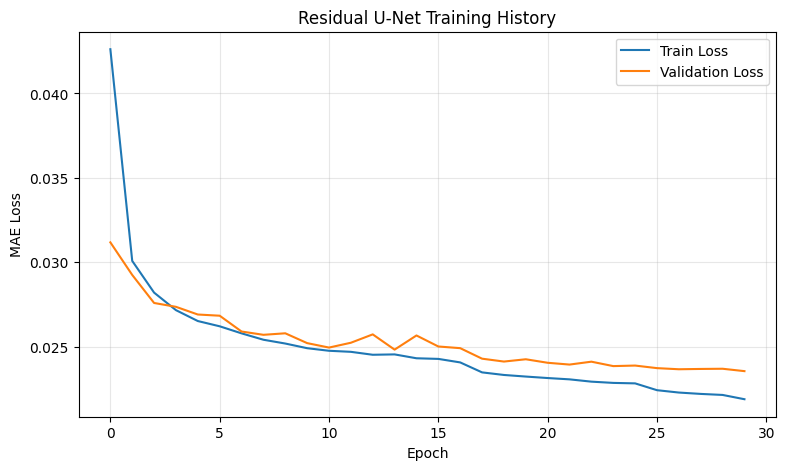

In [6]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE Loss")
plt.title("Residual U-Net Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [10]:
model = tf.keras.models.load_model(
    str(checkpoint_path)
)

results = {}

for category in CATEGORIES:
    ds = make_dataset(
        "test",
        categories=[category]
    )

    mae_scores = []
    mse_scores = []
    psnr_scores = []
    ssim_scores = []

    for x, y in ds:
        pred = model(x, training=False)
        pred = tf.clip_by_value(pred, 0.0, 1.0)

        # เฉลี่ยแกนความสูง ความกว้าง และช่องสี ได้หนึ่งค่าต่อภาพ
        error = y - pred

        mae = tf.reduce_mean(
            tf.abs(error), axis=[1, 2, 3]
        )
        mse = tf.reduce_mean(
            tf.square(error), axis=[1, 2, 3]
        )

        psnr = tf.image.psnr(
            y, pred, max_val=1.0
        )
        ssim = tf.image.ssim(
            y, pred, max_val=1.0
        )

        mae_scores.extend(mae.numpy())
        mse_scores.extend(mse.numpy())
        psnr_scores.extend(psnr.numpy())
        ssim_scores.extend(ssim.numpy())

    results[category] = {
        "MAE": float(np.mean(mae_scores)),
        "MSE": float(np.mean(mse_scores)),
        "PSNR": float(np.mean(psnr_scores)),
        "SSIM": float(np.mean(ssim_scores))
    }

for category, scores in results.items():
    print(
        f"{category:12s} | "
        f"MAE: {scores['MAE']:.6f} | "
        f"MSE: {scores['MSE']:.6f} | "
        f"PSNR: {scores['PSNR']:.2f} dB | "
        f"SSIM: {scores['SSIM']:.4f}"
    )


noise        | MAE: 0.018654 | MSE: 0.000735 | PSNR: 33.01 dB | SSIM: 0.8978
blur         | MAE: 0.022864 | MSE: 0.002045 | PSNR: 32.63 dB | SSIM: 0.8477
noise_blur   | MAE: 0.031084 | MSE: 0.002937 | PSNR: 29.12 dB | SSIM: 0.7554


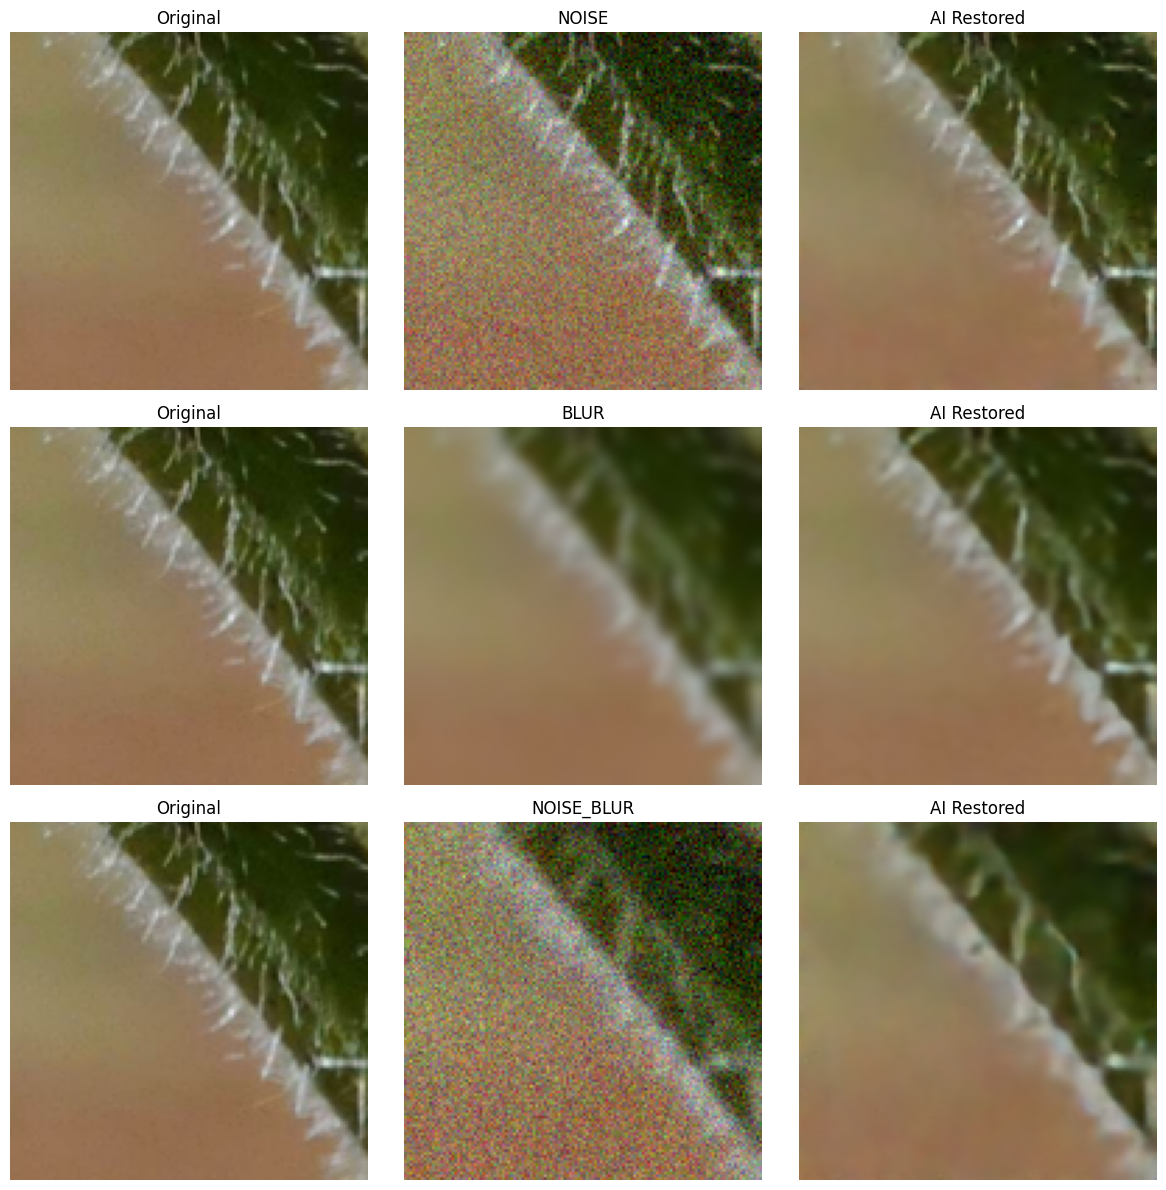

In [8]:
fig, axes = plt.subplots(
    3, 3, figsize=(12, 12)
)

for row, category in enumerate(CATEGORIES):
    ds = make_dataset(
        "test",
        categories=[category]
    )

    x, y = next(iter(ds))

    restored = model(
        x[:1], training=False
    )[0].numpy()

    images = [
        y[0].numpy(),
        x[0].numpy(),
        restored
    ]

    titles = [
        "Original",
        category.upper(),
        "AI Restored"
    ]

    for col, (img, title) in enumerate(zip(images, titles)):
        axes[row, col].imshow(
            np.clip(img, 0, 1)
        )
        axes[row, col].set_title(title)
        axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/restoration_results.png",
    dpi=200
)

plt.show()


In [9]:
model.save_weights("model.weights.h5")